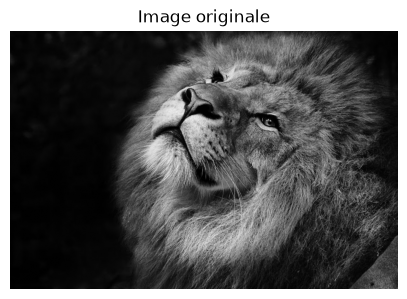

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
# Charger une image en niveaux de gris
img = cv2.imread('noir_et_blanc.jpg', cv2.IMREAD_GRAYSCALE)
plt.figure(figsize=(5,5))
plt.imshow(img, cmap='gray')
plt.title("Image originale")
plt.axis('off')
plt.show()

In [4]:
# Filtre moyenneur (flou)
kernel_blur = np.ones((3,3), np.float32) / 9
# Filtre de détection de contour (Sobel horizontal)
kernel_sobel = np.array([[-1, 0, 1],
[-2, 0, 2],
[-1, 0, 1]])
# Filtre d’accentuation
kernel_sharpen = np.array([[0, -1, 0],
[-1, 5,-1],
[0, -1, 0]])

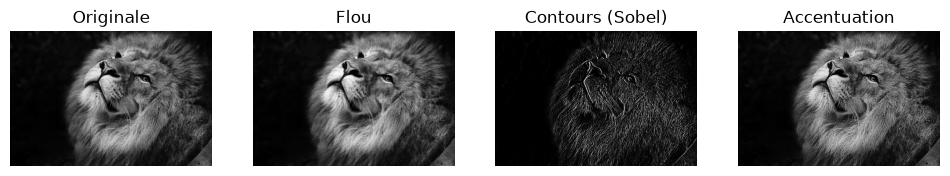

In [10]:
def apply_filter(img, kernel):
    return cv2.filter2D(img, -1, kernel)
filtered_blur = apply_filter(img, kernel_blur)
filtered_sobel = apply_filter(img, kernel_sobel)
filtered_sharp = apply_filter(img, kernel_sharpen)
titles = ['Originale', 'Flou', 'Contours (Sobel)', 'Accentuation']

images = [img, filtered_blur, filtered_sobel, filtered_sharp]
plt.figure(figsize=(12,3))
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.show()

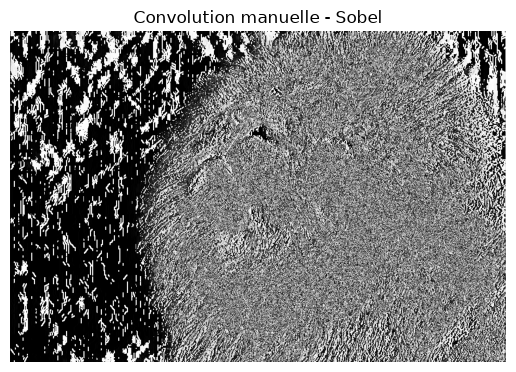

In [6]:
def manual_convolution(img, kernel):
    kh, kw = kernel.shape
    h, w = img.shape
    pad = kh // 2
    img_padded = np.pad(img, pad, mode='constant', constant_values=0)
    output = np.zeros_like(img)
    for i in range(h):
        for j in range(w):
            region = img_padded[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * kernel)
    return output

filtered_manual = manual_convolution(img, kernel_sobel)
plt.imshow(filtered_manual, cmap='gray')
plt.title("Convolution manuelle - Sobel")
plt.axis('off')
plt.show()

In [ ]:
#Questions
#1. Quelle est la différence visuelle entre les résultats des trois filtres ?
#2. Que se passe-t-il si on augmente la taille du kernel à 5×5 ?
#3. Pourquoi applique-t-on un padding ?
#4. Quelle serait l’effet d’une convolution avec stride = 2 ?
#5. En quoi cette opération ressemble-t-elle à ce qu’un CNN fait automatiquement ?
#6. Appliquer plusieurs filtres sur la même image.
#7. Créer un petit notebook interactif avec des sliders pour modifier les valeurs du kernel.